# Experiment 012: 1.5B base-to-GRPO three-seed analysis

Check of all three completed 012 base-start GRPO runs and
compare each seed with the matching 009 GSM8K-SFT-to-GRPO run. Seeds 1
and 2 are the prospectively fixed exploratory replication arms.

Generative exact match is primary. The letter-probability probe remains a
diagnostic reference. Tiers are rebuilt from the current subject mapping
before the matched comparison. Reading saved artifacts only
and does not need a GPU. Figures are saved to `analysis/figures/012_1/`.


In [1]:
# find the repo root and load the three matched route pairs
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import tier_of

RES = ROOT / "results"
FIG = ROOT / "analysis" / "figures" / "012_1"
FIG.mkdir(parents=True, exist_ok=True)

SEEDS = (0, 1, 2)
TIERS = ("easy", "medium", "hard")
COLORS = {0: "#4C78A8", 1: "#F58518", 2: "#54A24B"}
ROUTE_COLORS = {"base to GRPO": "#4C78A8", "SFT to GRPO": "#E45756"}

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def retier(rows):
    # rebuild tiers from the current subject mapping
    rebuilt = []
    for row in rows:
        row = dict(row)
        row["tier"] = tier_of(row["subject"])
        rebuilt.append(row)
    return rebuilt

def overall(rows):
    return float(np.mean([row["correct"] for row in rows]))

def grouped_accuracy(rows, field, value):
    selected = [row["correct"] for row in rows if row[field] == value]
    return float(np.mean(selected))

def load_run(path):
    return {
        "preds": retier(jsonl(path / "grpo_preds.jsonl")),
        "probe": retier(jsonl(path / "grpo_logprob_preds.jsonl")),
        "train": jload(path / "grpo_trainlog.json"),
        "eval": jload(path / "grpo_eval.json"),
        "probe_eval": jload(path / "grpo_logprob.json"),
        "manifest": jload(path / "manifest.json"),
    }

def metric_series(rows, key):
    selected = [row for row in rows if key in row and "step" in row]
    return (
        np.array([row["step"] for row in selected]),
        np.array([row[key] for row in selected], dtype=float),
    )

def smooth(values, window=15):
    # use a rolling mean because rollout metrics are noisy
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

BASE = {
    seed: load_run(RES / f"012_COLAB_FULL_B15_base_grpo_seed{seed}")
    for seed in SEEDS
}
WARM = {
    seed: load_run(RES / f"009_COLAB_FULL_B15_sft_grpo_seed{seed}")
    for seed in SEEDS
}
RAW_GEN = retier(jsonl(RES / "base_evals" / "012_COLAB_FULL_B15" / "base_preds.jsonl"))
RAW_PROBE = retier(jsonl(RES / "base_evals" / "012_COLAB_FULL_B15" / "base_logprob_preds.jsonl"))

for seed in SEEDS:
    reward_steps = [row["step"] for row in BASE[seed]["train"] if "reward" in row]
    assert reward_steps == list(range(1, 501)), f"seed {seed}: incomplete training history"
    for route in (BASE, WARM):
        assert len(route[seed]["preds"]) == 1884
        assert len(route[seed]["probe"]) == 1884
        assert route[seed]["manifest"]["seed"] == seed
    left, right = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    assert len(left) == len(right) == 1884
    assert BASE[seed]["manifest"]["gpu"]["device"] == "NVIDIA A100-SXM4-80GB"
    if seed in (1, 2):
        assert BASE[seed]["manifest"]["config"]["exec"]["allow_oom_fallback"] is False

assert len(RAW_GEN) == len(RAW_PROBE) == 1884
print("loaded three complete 012 runs and three matched 009 runs")


loaded three complete 012 runs and three matched 009 runs


## 1. Run health and completion

Completion checks stay separate from the accuracy results.


In [2]:
# summarise completion, environment and memory for all three base-route seeds
health_rows = []
for seed, data in BASE.items():
    manifest = data["manifest"]
    timings = manifest["timings_sec"]
    reward_rows = [row for row in data["train"] if "reward" in row]
    health_rows.append({
        "seed": seed,
        "status": "original" if seed == 0 else "exploratory",
        "steps": len(reward_rows),
        "gen_rows": len(data["preds"]),
        "probe_rows": len(data["probe"]),
        "dtype": manifest.get("resolved_dtype") or "auto (legacy)",
        "gpu": manifest["gpu"]["device"],
        "peak_vram_gb": manifest["gpu"]["peak_vram_gb"],
        "train_hours": timings["grpo_train"] / 3600,
        "gen_eval_hours": timings["grpo_eval"] / 3600,
    })
health_tbl = pd.DataFrame(health_rows).set_index("seed")
display(health_tbl.round(3))


,status,steps,gen_rows,probe_rows,dtype,gpu,peak_vram_gb,train_hours,gen_eval_hours
seed,,,,,,,,,
0,original,500,1884,1884,bfloat16,NVIDIA A100-SXM4-80GB,35.134,5.039,1.075
1,exploratory,500,1884,1884,bfloat16,NVIDIA A100-SXM4-80GB,35.134,4.767,1.071
2,exploratory,500,1884,1884,bfloat16,NVIDIA A100-SXM4-80GB,35.134,4.867,1.109


## 2. GRPO training behaviour

The same reward and rollout diagnostics are shown for each seed. The format
reward is divided by its 0.2 weight so it reads as rollout compliance.


saved fig01_training_rewards


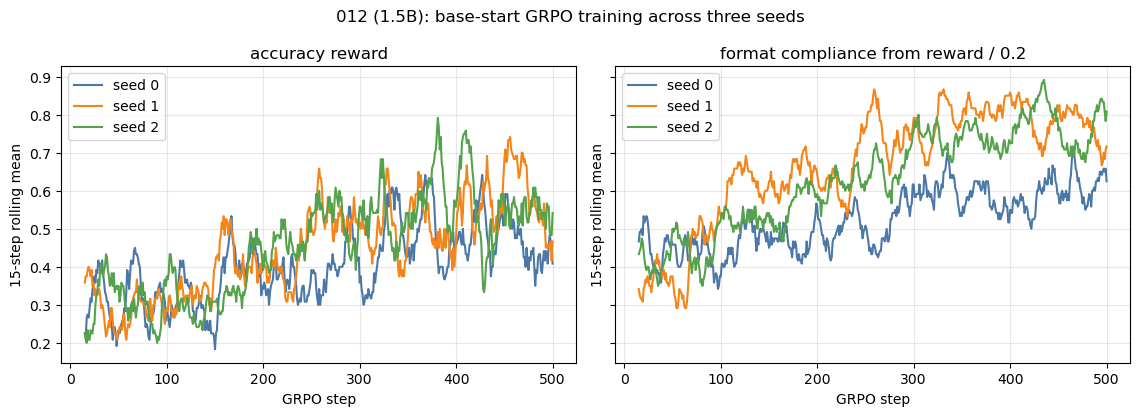

In [3]:
# compare accuracy and format reward across all 500 GRPO steps
window = 15
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for seed, data in BASE.items():
    steps, accuracy_reward = metric_series(data["train"], "rewards/accuracy_reward/mean")
    _, format_reward = metric_series(data["train"], "rewards/format_reward/mean")
    axes[0].plot(steps[window - 1:], smooth(accuracy_reward, window), color=COLORS[seed], label=f"seed {seed}")
    axes[1].plot(steps[window - 1:], smooth(format_reward, window) / 0.2, color=COLORS[seed], label=f"seed {seed}")
axes[0].set_title("accuracy reward")
axes[1].set_title("format compliance from reward / 0.2")
for ax in axes:
    ax.set_xlabel("GRPO step")
    ax.set_ylabel("15-step rolling mean")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("012 (1.5B): base-start GRPO training across three seeds")
fig.tight_layout()
save(fig, "fig01_training_rewards")
plt.show()


saved fig02_training_diagnostics


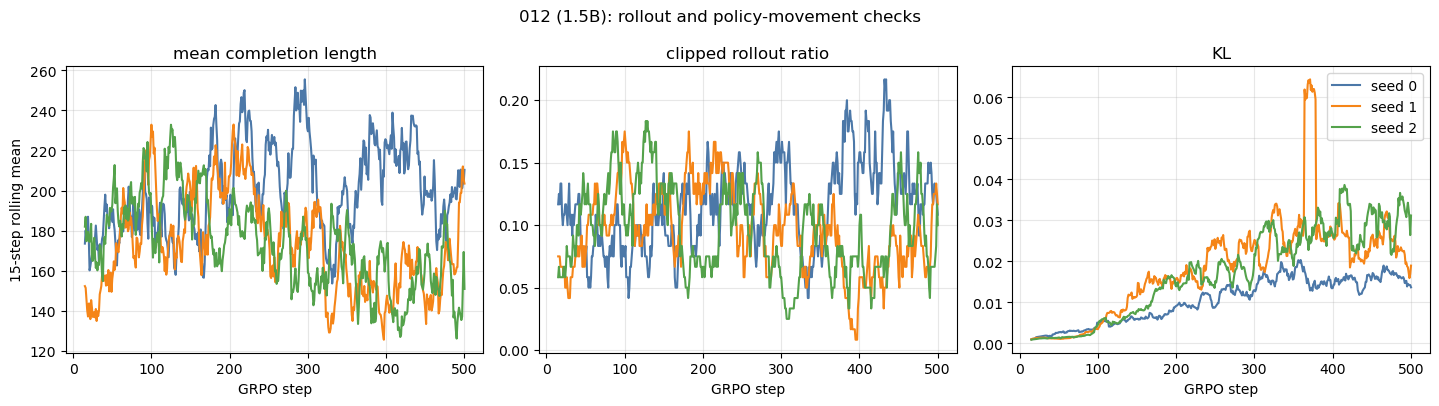

In [4]:
# compare rollout length, clipping and KL without hiding seed variation
panels = [
    ("completions/mean_length", "mean completion length"),
    ("completions/clipped_ratio", "clipped rollout ratio"),
    ("kl", "KL"),
]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.1))
for ax, (key, title) in zip(axes, panels):
    for seed, data in BASE.items():
        steps, values = metric_series(data["train"], key)
        ax.plot(steps[window - 1:], smooth(values, window), color=COLORS[seed], label=f"seed {seed}")
    ax.set_title(title)
    ax.set_xlabel("GRPO step")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("15-step rolling mean")
axes[-1].legend()
fig.suptitle("012 (1.5B): rollout and policy-movement checks")
fig.tight_layout()
save(fig, "fig02_training_diagnostics")
plt.show()


## 3. Three-seed base-to-GRPO endpoint

The shared raw-base result provides the before-training reference. The three
post-GRPO seeds show whether the accuracy gain and format collapse repeat.


saved fig03_raw_to_grpo_by_tier


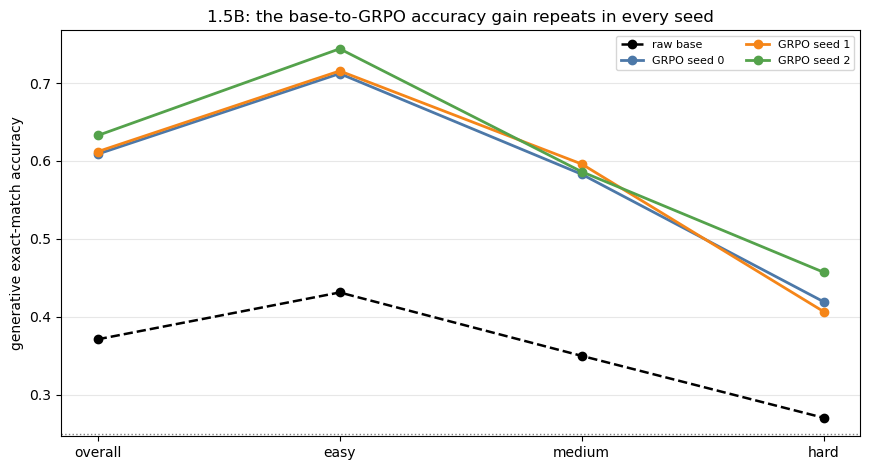

In [5]:
# compare the raw base with all three base-route endpoints by tier
labels = ("overall", *TIERS)
raw_values = [overall(RAW_GEN)] + [grouped_accuracy(RAW_GEN, "tier", tier) for tier in TIERS]
seed_values = {
    seed: [overall(data["preds"])] + [grouped_accuracy(data["preds"], "tier", tier) for tier in TIERS]
    for seed, data in BASE.items()
}

fig, ax = plt.subplots(figsize=(8.8, 4.8))
xpos = np.arange(len(labels))
ax.plot(xpos, raw_values, "o--", color="black", lw=1.8, label="raw base")
for seed in SEEDS:
    ax.plot(xpos, seed_values[seed], "o-", color=COLORS[seed], lw=2, label=f"GRPO seed {seed}")
ax.axhline(0.25, color="grey", ls=":", lw=1)
ax.set_xticks(xpos)
ax.set_xticklabels(labels)
ax.set_ylabel("generative exact-match accuracy")
ax.set_title("1.5B: the base-to-GRPO accuracy gain repeats in every seed")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, "fig03_raw_to_grpo_by_tier")
plt.show()


saved fig04_accuracy_format_states


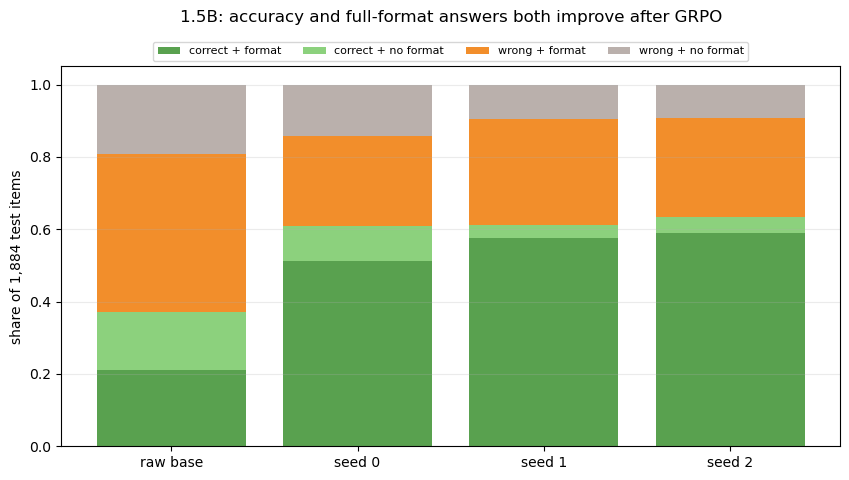

,correct + format,correct + no format,wrong + format,wrong + no format
raw base,0.2118,0.1592,0.4374,0.1916
seed 0,0.5111,0.0977,0.2500,0.1412
seed 1,0.5759,0.0361,0.2941,0.0939
seed 2,0.5897,0.0430,0.2744,0.0929


In [6]:
# split every endpoint into correctness and format states
state_labels = ("correct + format", "correct + no format", "wrong + format", "wrong + no format")
state_colors = ("#59A14F", "#8CD17D", "#F28E2B", "#BAB0AC")
conditions = [("raw base", RAW_GEN)] + [(f"seed {seed}", BASE[seed]["preds"]) for seed in SEEDS]
state_values = []
for _, rows in conditions:
    state_values.append([
        np.mean([row["correct"] and row["format_ok"] for row in rows]),
        np.mean([row["correct"] and not row["format_ok"] for row in rows]),
        np.mean([not row["correct"] and row["format_ok"] for row in rows]),
        np.mean([not row["correct"] and not row["format_ok"] for row in rows]),
    ])
state_values = np.array(state_values)

fig, ax = plt.subplots(figsize=(8.6, 4.9))
bottom = np.zeros(len(conditions))
for column, (label, color) in enumerate(zip(state_labels, state_colors)):
    ax.bar(range(len(conditions)), state_values[:, column], bottom=bottom, color=color, label=label)
    bottom += state_values[:, column]
ax.set_xticks(range(len(conditions)))
ax.set_xticklabels([label for label, _ in conditions])
ax.set_ylabel("share of 1,884 test items")
ax.set_title("1.5B: accuracy and full-format answers both improve after GRPO", pad=32)
ax.legend(fontsize=8, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.grid(alpha=0.25, axis="y")
fig.tight_layout()
save(fig, "fig04_accuracy_format_states")
plt.show()

format_tbl = pd.DataFrame(
    state_values,
    index=[label for label, _ in conditions],
    columns=state_labels,
)
display(format_tbl.round(4))


## 4. Matched warm-start comparison

Each comparison uses the same seed and the same 1,884 MMLU items. Positive
deltas mean the GSM8K SFT warm start produced the stronger GRPO endpoint.
Holm correction is applied across the three overall seed comparisons.


saved fig05_matched_route_endpoints


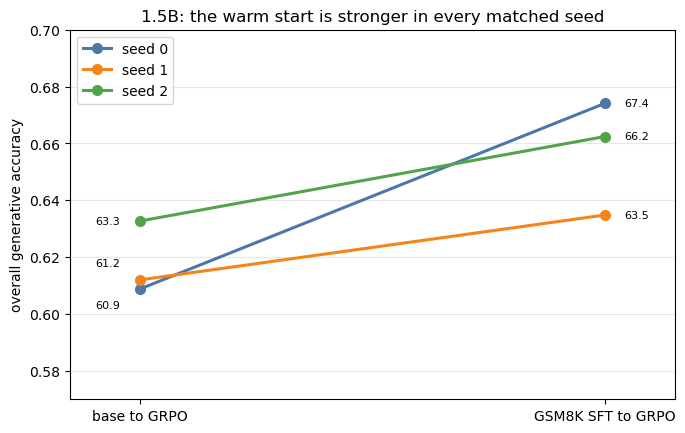

,base_grpo,warm_grpo,warm_minus_base,ci_low,ci_high,mcnemar_p,base_only,warm_only,holm_p,reading
seed,,,,,,,,,,
0,0.60881,0.67410,0.06529,0.04406,0.08652,0.00000,151,274,0.00000,material warm advantage
1,0.61200,0.63482,0.02282,0.00159,0.04352,0.03676,181,224,0.03676,material warm advantage
2,0.63270,0.66242,0.02972,0.00902,0.04989,0.00494,164,220,0.00988,material warm advantage


In [7]:
# calculate the registered matched-seed route comparison
route_rows = []
raw_p = []
for seed in SEEDS:
    base_rows, warm_rows = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    base_correct = [row["correct"] for row in base_rows]
    warm_correct = [row["correct"] for row in warm_rows]
    delta, low, high = paired_delta_ci(base_correct, warm_correct, seed=500 + seed)
    base_only = sum(a and not b for a, b in zip(base_correct, warm_correct))
    warm_only = sum((not a) and b for a, b in zip(base_correct, warm_correct))
    p_value = mcnemar_exact(warm_only, base_only)
    raw_p.append(p_value)
    route_rows.append({
        "seed": seed,
        "base_grpo": np.mean(base_correct),
        "warm_grpo": np.mean(warm_correct),
        "warm_minus_base": delta,
        "ci_low": low,
        "ci_high": high,
        "mcnemar_p": p_value,
        "base_only": base_only,
        "warm_only": warm_only,
    })
adjusted = holm(raw_p)
for row, adjusted_p in zip(route_rows, adjusted):
    row["holm_p"] = adjusted_p
    if abs(row["warm_minus_base"]) >= 0.02 and adjusted_p < 0.05:
        row["reading"] = "material warm advantage" if row["warm_minus_base"] > 0 else "material base advantage"
    elif row["ci_low"] >= -0.02 and row["ci_high"] <= 0.02:
        row["reading"] = "equivalent"
    else:
        row["reading"] = "inconclusive"
route_tbl = pd.DataFrame(route_rows).set_index("seed")

fig, ax = plt.subplots(figsize=(7.8, 4.8))
for seed, row in route_tbl.iterrows():
    values = [row["base_grpo"], row["warm_grpo"]]
    ax.plot([0, 1], values, "o-", lw=2.2, ms=7, color=COLORS[seed], label=f"seed {seed}")
    left_offset = {0: -12, 1: 12, 2: 0}[seed]
    ax.annotate(f"{100 * values[0]:.1f}", (0, values[0]), xytext=(-14, left_offset), textcoords="offset points", ha="right", va="center", fontsize=8)
    ax.annotate(f"{100 * values[1]:.1f}", (1, values[1]), xytext=(14, 0), textcoords="offset points", ha="left", va="center", fontsize=8)
ax.set_xlim(-0.15, 1.15)
ax.set_xticks([0, 1])
ax.set_xticklabels(["base to GRPO", "GSM8K SFT to GRPO"])
ax.set_ylabel("overall generative accuracy")
ax.set_ylim(0.57, 0.70)
ax.set_title("1.5B: the warm start is stronger in every matched seed")
ax.grid(alpha=0.3, axis="y")
ax.legend()
save(fig, "fig05_matched_route_endpoints")
plt.show()

display(route_tbl.round(5))


saved fig06_route_delta_by_tier


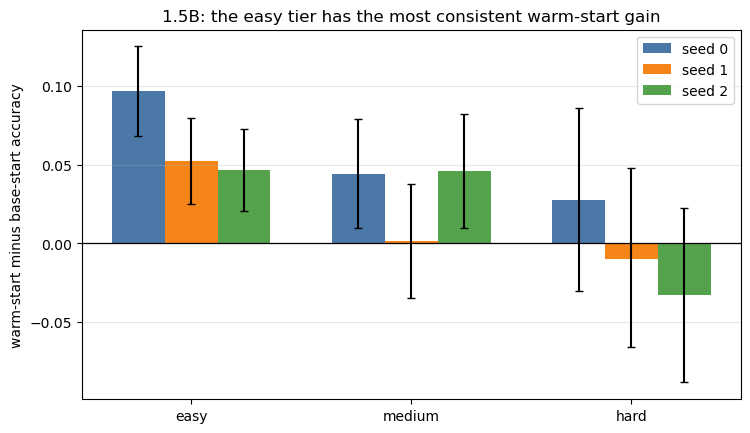

delta  ci_low  ci_high
seed tier                           
0    easy    0.0967  0.0683   0.1251
     medium  0.0443  0.0099   0.0788
     hard    0.0278 -0.0303   0.0859
1    easy    0.0523  0.0250   0.0796
     medium  0.0016 -0.0345   0.0378
     hard   -0.0101 -0.0657   0.0480
2    easy    0.0466  0.0205   0.0728
     medium  0.0460  0.0099   0.0821
     hard   -0.0328 -0.0884   0.0227

In [8]:
# split the matched route difference by tier for every seed
tier_rows = []
for seed in SEEDS:
    base_rows, warm_rows = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    for tier in TIERS:
        pairs = [(a["correct"], b["correct"]) for a, b in zip(base_rows, warm_rows) if a["tier"] == tier]
        base_correct = [a for a, _ in pairs]
        warm_correct = [b for _, b in pairs]
        delta, low, high = paired_delta_ci(base_correct, warm_correct, seed=600 + 10 * seed + TIERS.index(tier))
        tier_rows.append({"seed": seed, "tier": tier, "delta": delta, "ci_low": low, "ci_high": high})
tier_tbl = pd.DataFrame(tier_rows)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
xpos = np.arange(len(TIERS))
width = 0.24
for index, seed in enumerate(SEEDS):
    selected = tier_tbl[tier_tbl["seed"] == seed].set_index("tier").loc[list(TIERS)]
    values = selected["delta"].to_numpy()
    errors = np.vstack([values - selected["ci_low"].to_numpy(), selected["ci_high"].to_numpy() - values])
    positions = xpos + (index - 1) * width
    ax.bar(positions, values, width, yerr=errors, capsize=3, color=COLORS[seed], label=f"seed {seed}")
ax.axhline(0, color="black", lw=0.9)
ax.set_xticks(xpos)
ax.set_xticklabels(TIERS)
ax.set_ylabel("warm-start minus base-start accuracy")
ax.set_title("1.5B: the easy tier has the most consistent warm-start gain")
ax.grid(alpha=0.3, axis="y")
ax.legend()
save(fig, "fig06_route_delta_by_tier")
plt.show()

display(tier_tbl.set_index(["seed", "tier"]).round(4))


## 5. Format, response length and the knowledge probe

These diagnostics separate improved answer expression from changes in the
underlying letter preference. The raw-base probe is shared across 012 seeds.


saved fig07_route_diagnostics


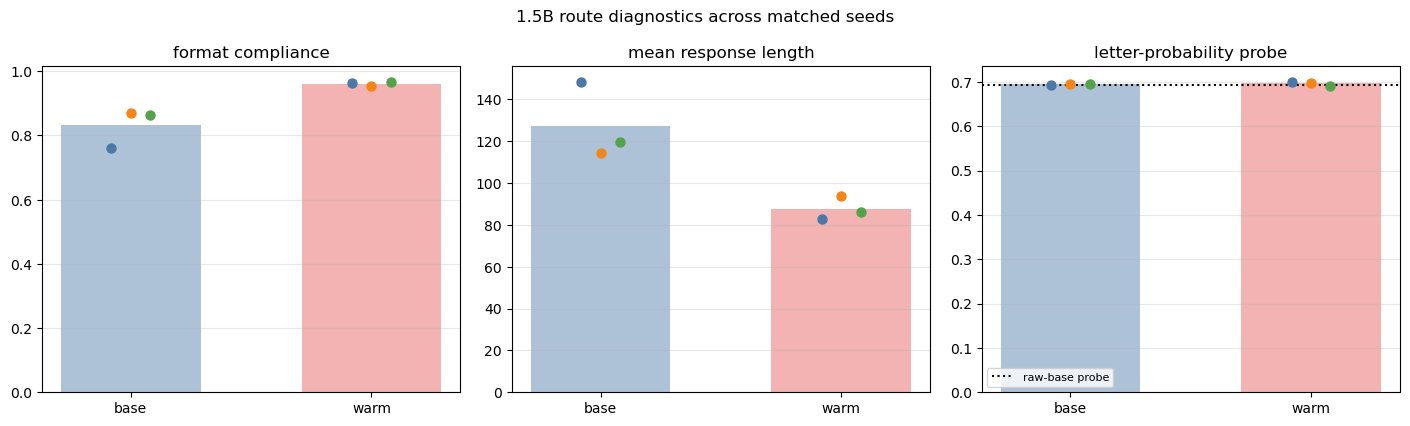

format  mean_length  probe_accuracy  gen_accuracy
route        seed                                                   
base to GRPO 0     0.7611     148.3015          0.6937        0.6088
             1     0.8700     114.5111          0.6943        0.6120
             2     0.8641     119.5159          0.6959        0.6327
SFT to GRPO  0     0.9644      82.8259          0.7001        0.6741
             1     0.9544      93.6173          0.6980        0.6348
             2     0.9671      85.9469          0.6916        0.6624

In [9]:
# compare route diagnostics while keeping all three seeds visible
diagnostic_rows = []
for label, runs in (("base to GRPO", BASE), ("SFT to GRPO", WARM)):
    for seed, data in runs.items():
        diagnostic_rows.append({
            "route": label,
            "seed": seed,
            "format": float(np.mean([row["format_ok"] for row in data["preds"]])),
            "mean_length": float(np.mean([row["n_tokens"] for row in data["preds"]])),
            "probe_accuracy": overall(data["probe"]),
            "gen_accuracy": overall(data["preds"]),
        })
diagnostic_tbl = pd.DataFrame(diagnostic_rows)

panels = [("format", "format compliance"), ("mean_length", "mean response length"), ("probe_accuracy", "letter-probability probe")]
fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.3))
for ax, (metric, title) in zip(axes, panels):
    for x, route in enumerate(("base to GRPO", "SFT to GRPO")):
        values = diagnostic_tbl.loc[diagnostic_tbl["route"] == route, metric].to_numpy()
        ax.bar(x, values.mean(), width=0.58, color=ROUTE_COLORS[route], alpha=0.45)
        for index, value in enumerate(values):
            ax.scatter(x + (index - 1) * 0.08, value, color=COLORS[index], s=42, zorder=3)
    if metric == "probe_accuracy":
        ax.axhline(overall(RAW_PROBE), color="black", ls=":", lw=1.5, label="raw-base probe")
        ax.legend(fontsize=8)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["base", "warm"])
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("1.5B route diagnostics across matched seeds")
fig.tight_layout()
save(fig, "fig07_route_diagnostics")
plt.show()

display(diagnostic_tbl.set_index(["route", "seed"]).round(4))


saved fig08_probe_movement


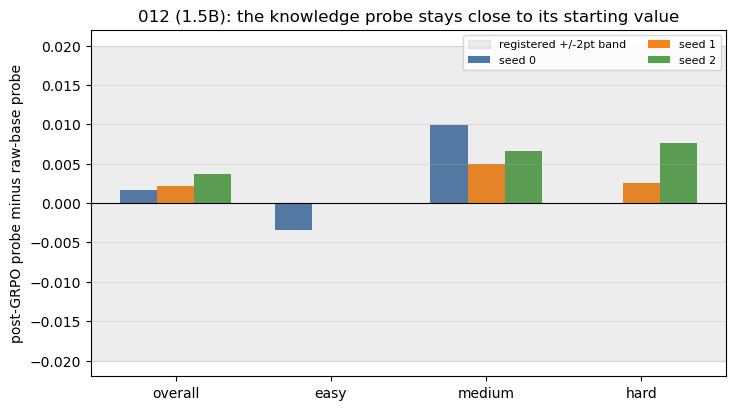

,overall,easy,medium,hard
seed,,,,
0,0.0016,-0.0034,0.0099,0.0000
1,0.0021,0.0000,0.0049,0.0025
2,0.0037,0.0000,0.0066,0.0076


In [10]:
# measure base-route probe movement against the shared raw-base reference
raw_probe_by_tier = {tier: grouped_accuracy(RAW_PROBE, "tier", tier) for tier in TIERS}
raw_probe_overall = overall(RAW_PROBE)
probe_rows = []
for seed, data in BASE.items():
    row = {"seed": seed, "overall": overall(data["probe"]) - raw_probe_overall}
    for tier in TIERS:
        row[tier] = grouped_accuracy(data["probe"], "tier", tier) - raw_probe_by_tier[tier]
    probe_rows.append(row)
probe_tbl = pd.DataFrame(probe_rows).set_index("seed")

fig, ax = plt.subplots(figsize=(8.2, 4.5))
labels = ["overall", *TIERS]
xpos = np.arange(len(labels))
width = 0.24
for index, seed in enumerate(SEEDS):
    values = probe_tbl.loc[seed, labels].to_numpy(dtype=float)
    ax.bar(xpos + (index - 1) * width, values, width, color=COLORS[seed], label=f"seed {seed}")
ax.axhspan(-0.02, 0.02, color="grey", alpha=0.14, label="registered +/-2pt band")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(labels)
ax.set_ylabel("post-GRPO probe minus raw-base probe")
ax.set_title("012 (1.5B): the knowledge probe stays close to its starting value")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8, ncol=2)
save(fig, "fig08_probe_movement")
plt.show()

display(probe_tbl.round(4))


saved fig09_subject_route_matrix


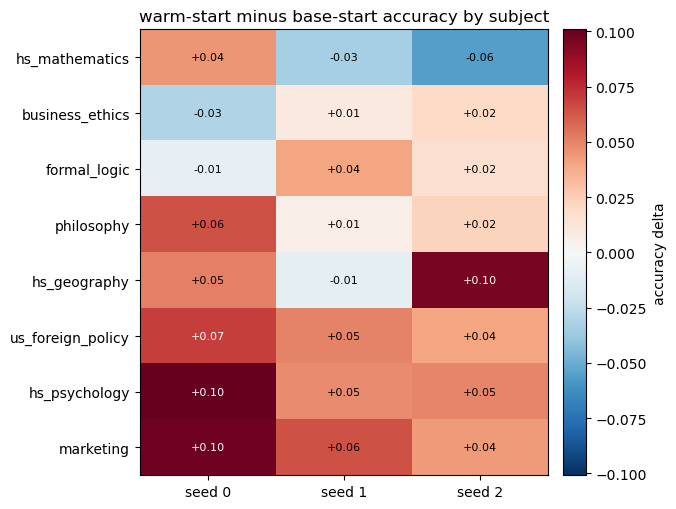

,seed_0,seed_1,seed_2
business_ethics,-0.0300,0.0100,0.0200
formal_logic,-0.0079,0.0397,0.0159
high_school_geography,0.0505,-0.0101,0.0960
high_school_mathematics,0.0444,-0.0333,-0.0556
high_school_psychology,0.1009,0.0477,0.0495
marketing,0.0983,0.0641,0.0427
philosophy,0.0643,0.0064,0.0225
us_foreign_policy,0.0700,0.0500,0.0400


In [11]:
# show where the matched route difference agrees or changes across subjects
subjects = sorted({row["subject"] for row in BASE[0]["preds"]})
subject_values = np.zeros((len(subjects), len(SEEDS)))
for column, seed in enumerate(SEEDS):
    base_rows, warm_rows = align_pred_rows(BASE[seed]["preds"], WARM[seed]["preds"])
    for row_index, subject in enumerate(subjects):
        base_acc = grouped_accuracy(base_rows, "subject", subject)
        warm_acc = grouped_accuracy(warm_rows, "subject", subject)
        subject_values[row_index, column] = warm_acc - base_acc
order = np.argsort(subject_values.mean(axis=1))
ordered = subject_values[order]
labels = [subjects[index].replace("high_school_", "hs_") for index in order]
limit = max(abs(ordered.min()), abs(ordered.max()))

fig, ax = plt.subplots(figsize=(6.8, 5.2))
image = ax.imshow(ordered, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto", interpolation="nearest")
for row_index in range(ordered.shape[0]):
    for column in range(ordered.shape[1]):
        color = heatmap_text_color(image, ordered[row_index, column])
        ax.text(column, row_index, f"{ordered[row_index, column]:+.2f}", ha="center", va="center", fontsize=8, color=color)
ax.set_xticks(range(len(SEEDS)))
ax.set_xticklabels([f"seed {seed}" for seed in SEEDS])
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_title("warm-start minus base-start accuracy by subject")
colorbar = fig.colorbar(image, ax=ax, pad=0.03)
colorbar.set_label("accuracy delta")
fig.tight_layout()
save(fig, "fig09_subject_route_matrix")
plt.show()

subject_tbl = pd.DataFrame(subject_values, index=subjects, columns=[f"seed_{seed}" for seed in SEEDS])
display(subject_tbl.round(4))


## 6. Compute and exact endpoint tables

The shared base evaluation is excluded because seeds 1 and 2 reused it. The
bars therefore show the comparable work performed inside each 012 arm.


saved fig10_compute_by_seed


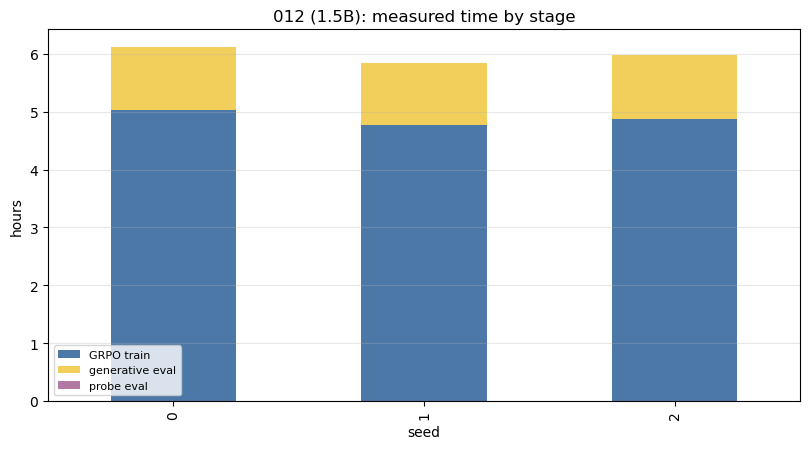

,GRPO train,generative eval,probe eval
seed,,,
0,5.039,1.075,0.007
1,4.767,1.071,0.007
2,4.867,1.109,0.007


In [12]:
# compare measured GRPO training and evaluation time across seeds
compute_rows = []
for seed, data in BASE.items():
    timings = data["manifest"]["timings_sec"]
    compute_rows.append({
        "seed": seed,
        "GRPO train": timings["grpo_train"] / 3600,
        "generative eval": timings["grpo_eval"] / 3600,
        "probe eval": timings["grpo_logprob_eval"] / 3600,
    })
compute_tbl = pd.DataFrame(compute_rows).set_index("seed")
ax = compute_tbl.plot(kind="bar", stacked=True, figsize=(8.2, 4.6), color=["#4C78A8", "#F2CF5B", "#B279A2"])
ax.set_ylabel("hours")
ax.set_xlabel("seed")
ax.set_title("012 (1.5B): measured time by stage")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8)
fig = ax.get_figure()
fig.tight_layout()
save(fig, "fig10_compute_by_seed")
plt.show()

display(compute_tbl.round(3))


In [13]:
# keep the exact endpoint values used by the figures in one table
endpoint_rows = []
for route, runs in (("base to GRPO", BASE), ("SFT to GRPO", WARM)):
    for seed, data in runs.items():
        row = {
            "route": route,
            "seed": seed,
            "overall": overall(data["preds"]),
            "format": float(np.mean([item["format_ok"] for item in data["preds"]])),
            "mean_length": float(np.mean([item["n_tokens"] for item in data["preds"]])),
            "probe_overall": overall(data["probe"]),
        }
        for tier in TIERS:
            row[tier] = grouped_accuracy(data["preds"], "tier", tier)
        endpoint_rows.append(row)
endpoint_tbl = pd.DataFrame(endpoint_rows).set_index(["route", "seed"])
display(endpoint_tbl.round(4))


overall  format  mean_length  probe_overall    easy  \
route        seed                                                        
base to GRPO 0      0.6088  0.7611     148.3015         0.6937  0.7122   
             1      0.6120  0.8700     114.5111         0.6943  0.7156   
             2      0.6327  0.8641     119.5159         0.6959  0.7440   
SFT to GRPO  0      0.6741  0.9644      82.8259         0.7001  0.8089   
             1      0.6348  0.9544      93.6173         0.6980  0.7679   
             2      0.6624  0.9671      85.9469         0.6916  0.7907   

                   medium    hard  
route        seed                  
base to GRPO 0     0.5829  0.4192  
             1     0.5961  0.4066  
             2     0.5862  0.4571  
SFT to GRPO  0     0.6273  0.4470  
             1     0.5977  0.3965  
             2     0.6322  0.4242

## Cross-referenced conclusion

All three 012 base-start runs completed normally on A100-80GB. Each has
exactly 500 GRPO steps and complete 1,884-item generative and probe
evaluations. The new arms used no execution fallback.

Base-to-GRPO accuracy is 60.9%, 61.2% and 63.3%. Every seed is much stronger
than the shared 37.1% raw-base endpoint, so the gain is not a seed-0 accident.
Full-format compliance is 76.1%, 87.0% and 86.4%. Unlike 0.5B, direct GRPO at
1.5B does not produce a systematic format collapse.

The matched warm-start comparison has one common reading. Warm minus base is
+6.5, +2.3 and +3.0 points. All three differences meet the registered material
threshold and remain significant after Holm correction. The GSM8K warm start
therefore gives a replicated overall advantage at 1.5B, although the size of
the advantage changes across seeds.

The easy tier has the clearest repeated benefit, from +4.7 to +9.7 points.
Medium gains are mixed in size, from +0.2 to +4.6 points. Hard-tier estimates
are +2.8, -1.0 and -3.3 points, and all three intervals cross zero. There is no
decisive hard-tier route difference at 1.5B.

The post-GRPO letter probe remains within half a point of the shared raw-base
probe in every seed. This supports the existing elicitation interpretation:
the large generative change is mainly in answer production and extraction,
not a measurable increase in encoded MMLU knowledge.
